### Prof. Alfio Ferrara

# Usare gli embedding

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo allenato noi i vettori delle parole, in un mondo di 52 parole. Qui usiamo vettori **già allenati da altri**, su una quantità enorme di testo italiano: 500 mila parole, 300 numeri per ciascuna.

Nella prima parte vediamo che cosa si può fare con questi vettori: misurare somiglianze, fare operazioni tra parole, combinare parole in frasi. Nella seconda parte li usiamo come strumenti di lavoro su testi: un motore di ricerca, un lessico tematico, un confronto tra lessici di epoche diverse.

## Un modello già allenato

Carichiamo il modello italiano di spaCy, lo stesso che usiamo da vari notebook per spezzare i testi in token. Oltre alla grammatica contiene una tabella di vettori: una riga per ogni parola, come la matrice $W_1$ del notebook precedente, ma molto più grande.

In [1]:
import json
import os
import pickle
import random
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.cluster import KMeans
import spacy

nlp = spacy.load('it_core_news_lg')
stop_words = nlp.Defaults.stop_words


def vec(word):
    return nlp.vocab[word].vector


def unit(v):
    return v / np.linalg.norm(v)


print('tabella dei vettori:', nlp.vocab.vectors.shape[0], 'parole,', nlp.vocab.vectors.shape[1], 'numeri ciascuna')
print('\nil vettore di «gatto» (primi 10 numeri):', np.round(vec('gatto')[:10], 2))
print('lunghezza del vettore:', round(float(np.linalg.norm(vec('gatto'))), 2))
for w in ['gatto', 'gattino', 'gattopardo', 'xyzzy']:
    print(f'{w!r:14} nella tabella: {nlp.vocab.has_vector(w)}')

tabella dei vettori: 500000 parole, 300 numeri ciascuna

il vettore di «gatto» (primi 10 numeri): [ 1.74  0.41 -2.74 -0.52  0.28  2.06  2.22 -1.68  4.62  0.09]
lunghezza del vettore: 31.6
'gatto'        nella tabella: True
'gattino'      nella tabella: True
'gattopardo'   nella tabella: True
'xyzzy'        nella tabella: False


## Un momento di riflessione

- Quanti numeri ci sono in tutto nella tabella? Quanti ne avevamo nel notebook precedente?
- Guardate i primi dieci numeri del vettore di *gatto*. Ha senso chiedersi che cosa significa il terzo numero?
- *gattino* e *gattopardo* hanno un vettore, *xyzzy* no. Che cosa ci dice sulla tabella? Che cosa dobbiamo fare con le parole che non ci sono?
- Chi ha allenato questi vettori? Su quali testi? Con quale compito? Che cosa possiamo sapere del modo in cui sono stati ottenuti?

## Quanto sono simili due parole

Per confrontare due vettori usiamo il **coseno** dell'angolo tra loro, come per i documenti: vale 1 se hanno la stessa direzione, 0 se sono indipendenti, −1 se sono opposti.

In [2]:
def cosine(a, b):
    return float(unit(vec(a)) @ unit(vec(b)))


pairs = [('gatto', 'gattino'), ('gatto', 'cane'), ('gatto', 'automobile'), ('medico', 'dottore'), ('medico', 'ospedale'),
         ('caldo', 'freddo'), ('caldo', 'umido'), ('bello', 'brutto'), ('re', 'regina'), ('pane', 'computer')]
pd.DataFrame({'coseno': [cosine(a, b) for a, b in pairs]}, index=[f'{a} - {b}' for a, b in pairs]).round(2)

,coseno
gatto - gattino,0.84
gatto - cane,0.85
gatto - automobile,0.21
medico - dottore,0.73
medico - ospedale,0.49
caldo - freddo,0.84
caldo - umido,0.67
bello - brutto,0.60
re - regina,0.57
pane - computer,0.11


## Un momento di riflessione

- Quali coppie hanno la similarità più alta? Sono sinonimi?
- *caldo* e *freddo* sono contrari. Sono vicini o lontani? Che cosa vuol dire, per il modello, «simile»?
- *medico - ospedale* è alta, *pane - computer* bassa. Che cosa hanno in comune medico e ospedale? Sono la stessa cosa?
- Ricordate la differenza tra i vettori da classificazione e da contesto nel notebook precedente. Quale dei due ricorda questo comportamento?

## I vicini di una parola

Per cercare i vicini di una parola confrontiamo il suo vettore con quelli delle altre parole. Ci limitiamo alle 50 mila parole più frequenti, scritte in minuscolo e solo con lettere: la tabella contiene anche numeri, segni e forme rare che non ci interessano. I vettori sono ordinati per frequenza, quindi basta prendere le prime.

In [3]:
lexicon = []
for key in nlp.vocab.vectors.keys():
    if key in nlp.vocab.strings:
        w = nlp.vocab.strings[key]
        if w.isalpha() and w.islower():
            lexicon.append(w)
    if len(lexicon) == 50000:
        break

lexicon_matrix = np.array([unit(vec(w)) for w in lexicon])


def neighbors(word, k=8):
    s = lexicon_matrix @ unit(vec(word))
    return [lexicon[i] for i in np.argsort(-s) if lexicon[i] != word][:k]


probe = ['gatto', 'libertà', 'dottore', 'caldo', 'banca', 'rete', 'stato', 'chiesa']
pd.DataFrame({w: neighbors(w) for w in probe}).T.rename(columns=lambda i: f'{i + 1}°')

,1°,2°,3°,4°,5°,6°,7°,8°
gatto,cane,gattino,coniglio,felino,cucciolo,micio,animaletto,cagnolino
libertà,liberta,libert,liberalità,dignità,laicità,moralità,eguaglianza,uguaglianza
dottore,dottor,professore,professor,medico,urologo,ginecologo,neurologo,dottoressa
caldo,freddo,caldissimo,calda,umido,fresco,tiepido,calduccio,asciutto
banca,bancaria,bancario,bancari,banche,creditizia,credito,tesoreria,moneta
rete,infrastruttura,piattaforma,connettività,connessione,multipiattaforma,telecomunicazione,postazione,internet
stato,aveva,restato,avrebbe,rimasto,viene,intervenuto,sospettato,contestato
chiesa,chiesetta,basilica,cattedrale,cappella,parrocchia,sacrestia,sagrestia,parrocchiale


## Un momento di riflessione

- Per quali parole i vicini sono quelli che vi aspettate? Per quali no?
- *stato* ha vicini che sembrano non c'entrare con lo Stato. Perché? Quanti significati ha la parola?
- *rete* ha un solo significato nei vicini. Quale? Avevamo un'altra *rete* nel notebook precedente: che fine ha fatto il senso di pesca?
- *libertà* ha tra i vicini parole mal scritte o quasi uguali. Che cosa ci dice sui testi su cui il modello è stato allenato?
- Un vettore per parola, qualunque contesto. Che cosa succede alle parole con più significati?

## Una mappa e dei cluster

Scegliamo noi un piccolo lessico, sei categorie di otto parole, e guardiamo come il modello lo dispone. Come nel notebook precedente: mappa PCA a sinistra, matrice di similarità riordinata con il clustering a destra. I colori sono le nostre categorie, che il modello non conosce.

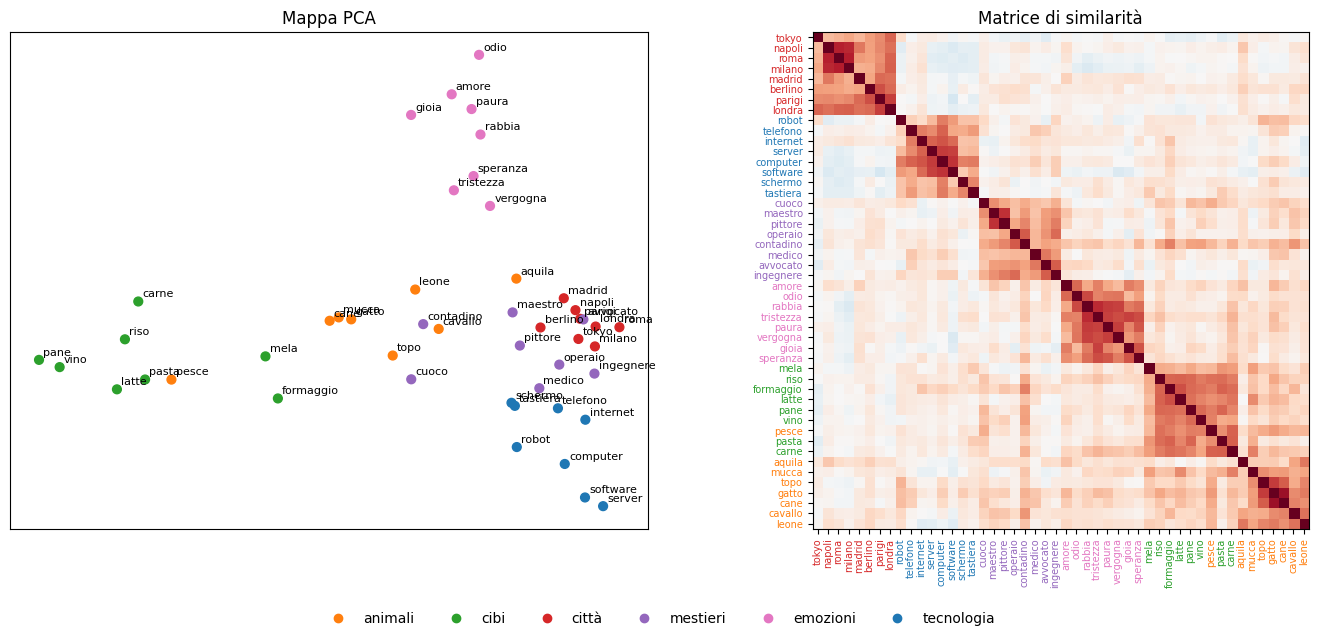

In [4]:
categories = {
    'animali': ['gatto', 'cane', 'cavallo', 'leone', 'topo', 'pesce', 'aquila', 'mucca'],
    'cibi': ['pane', 'pasta', 'formaggio', 'mela', 'vino', 'latte', 'carne', 'riso'],
    'città': ['roma', 'milano', 'parigi', 'londra', 'berlino', 'madrid', 'napoli', 'tokyo'],
    'mestieri': ['medico', 'avvocato', 'maestro', 'operaio', 'contadino', 'pittore', 'ingegnere', 'cuoco'],
    'emozioni': ['gioia', 'paura', 'rabbia', 'tristezza', 'speranza', 'amore', 'odio', 'vergogna'],
    'tecnologia': ['computer', 'internet', 'telefono', 'software', 'schermo', 'tastiera', 'server', 'robot'],
}
palette = dict(zip(categories, ['tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:pink', 'tab:blue']))
category_of = {w: c for c, ws in categories.items() for w in ws}
mini = list(category_of)


def pca2(X):
    Xc = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T


def draw_map(ax, P, words, colors, title='', fontsize=8):
    ax.scatter(P[:, 0], P[:, 1], c=colors, s=40, zorder=3)
    for (x, y), w in zip(P, words):
        ax.annotate(w, (x, y), fontsize=fontsize, xytext=(3, 3), textcoords='offset points')
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def draw_similarity(ax, X, words, colors, title=''):
    Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
    order = leaves_list(linkage(Xn, 'average', metric='cosine'))
    ax.imshow((Xn @ Xn.T)[order][:, order], cmap='RdBu_r', vmin=-1, vmax=1)
    labels = [words[i] for i in order]
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(labels, fontsize=7)
    for tick, i in zip(list(ax.get_xticklabels()) + list(ax.get_yticklabels()), list(order) * 2):
        tick.set_color(colors[i])
    ax.set_title(title)


X_mini = np.array([vec(w) for w in mini])
colors_mini = [palette[category_of[w]] for w in mini]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
draw_map(axes[0], pca2(X_mini), mini, colors_mini, 'Mappa PCA')
draw_similarity(axes[1], X_mini, mini, colors_mini, 'Matrice di similarità')
handles = [Line2D([], [], marker='o', color=c, linestyle='', label=n) for n, c in palette.items()]
fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Un momento di riflessione

- Le sei categorie sono separate? Quali sono più compatte, quali più sparse?
- Ci sono parole che finiscono vicino a una categoria diversa dalla nostra? Per quale motivo potrebbe essere?
- Nella mappa a sinistra i gruppi sono ben separati, nella matrice a destra ci sono blocchi dentro blocchi. Che cosa vediamo nella matrice che la mappa non mostra?
- Nessuno ha detto al modello che *roma* e *londra* sono città. Come lo ha capito?

## Operazioni tra parole

I vettori si possono sommare e sottrarre. Se la differenza tra due vettori cattura una relazione, per esempio quella tra *uomo* e *donna*, possiamo applicarla a un'altra parola:

$$\text{re} - \text{uomo} + \text{donna} \;\approx\; ?$$

Calcoliamo il vettore risultante e cerchiamo le parole più vicine, escludendo quelle di partenza.

In [5]:
def analogy(plus, minus, k=3, exclude=True):
    v = sum(vec(w) for w in plus) - sum(vec(w) for w in minus)
    s = lexicon_matrix @ unit(v)
    return [lexicon[i] for i in np.argsort(-s) if not exclude or lexicon[i] not in plus + minus][:k]


examples = [
    (['re', 'donna'], ['uomo'], 'regina'),
    (['francia', 'italiano'], ['italia'], 'francese'),
    (['cantava', 'mangiare'], ['cantare'], 'mangiava'),
    (['dollaro', 'inghilterra'], ['america'], 'sterlina'),
    (['roma', 'francia'], ['italia'], 'parigi'),
    (['zia', 'uomo'], ['donna'], 'zio'),
]
pd.DataFrame({
    'operazione': [' + '.join(p) + ' - ' + ' - '.join(m) for p, m, _ in examples],
    'atteso': [a for _, _, a in examples],
    'risultato': [', '.join(analogy(p, m)) for p, m, _ in examples],
    'senza escludere': [analogy(p, m, 1, exclude=False)[0] for p, m, _ in examples],
})

,operazione,atteso,risultato,senza escludere
0,re + donna - uomo,regina,"monarca, regina, sovrano",re
1,francia + italiano - italia,francese,"francese, tedesco, elvetico",francese
2,cantava + mangiare - cantare,mangiava,"mangiava, mangiavo, mangia",mangiava
3,dollaro + inghilterra - america,sterlina,"sterlina, yen, rialzo",dollaro
4,roma + francia - italia,parigi,"napoli, bologna, bari",roma
5,zia + uomo - donna,zio,"nonna, nipote, nonno",zia


## Un momento di riflessione

- Quali operazioni danno il risultato atteso? Quali no? C'è un criterio per capire quando funziona?
- *roma + francia - italia* non dà *parigi*. Che cosa dà? Che cosa ha sottratto il modello a *italia*?
- Che cosa succede se non escludiamo le parole di partenza? Perché la parola più vicina al risultato è spesso una di quelle da cui siamo partiti?
- Alcune operazioni mettono insieme relazioni diverse (femminile, plurale, tempo del verbo, nazionalità). Dove sono scritte queste relazioni, nel modello?
- Possiamo fidarci di un'analogia per scoprire qualcosa che non sappiamo? Che cosa servirebbe per verificarla?

## Una relazione è una direzione

Perché l'aritmetica a volte funziona? Se la differenza *donna - uomo* è più o meno la stessa per molte coppie, allora è una **direzione** nello spazio, e applicarla a una parola la sposta nella stessa direzione. Disegniamo sei coppie maschile-femminile con una freccia che va dalla forma maschile a quella femminile.

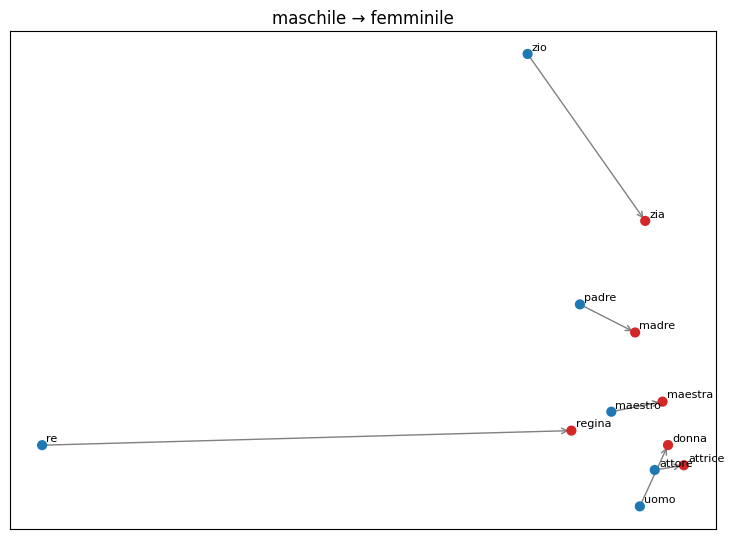

Coseno medio tra le differenze delle sei coppie: 0.48
principe + direzione: principessa, contessa, duchessa
professore + direzione: professoressa, ricercatrice, studentessa
dottore + direzione: dottoressa, professoressa, ginecologa
scrittore + direzione: scrittrice, autrice, poetessa


In [6]:
gender_pairs = [('re', 'regina'), ('uomo', 'donna'), ('zio', 'zia'), ('maestro', 'maestra'), ('padre', 'madre'), ('attore', 'attrice')]
gender_words = [w for p in gender_pairs for w in p]
P = pca2(np.array([vec(w) for w in gender_words]))
position = {w: P[i] for i, w in enumerate(gender_words)}

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for m, f in gender_pairs:
    ax.annotate('', xy=position[f], xytext=position[m], arrowprops=dict(arrowstyle='->', color='gray'))
draw_map(ax, P, gender_words, ['tab:blue' if i % 2 == 0 else 'tab:red' for i in range(len(gender_words))], 'maschile → femminile')
plt.tight_layout()
plt.show()

diffs = np.array([vec(f) - vec(m) for m, f in gender_pairs])
print('Coseno medio tra le differenze delle sei coppie:', round(float(np.mean([unit(a) @ unit(b) for i, a in enumerate(diffs) for b in diffs[i + 1:]])), 2))
mean_diff = diffs.mean(axis=0)
for w in ['principe', 'professore', 'dottore', 'scrittore']:
    s = lexicon_matrix @ unit(vec(w) + mean_diff)
    near = [lexicon[i] for i in np.argsort(-s) if lexicon[i] != w][:3]
    print(f"{w} + direzione: {', '.join(near)}")

## Un momento di riflessione

- Le frecce sono parallele? Quanto lo sono davvero, secondo il coseno tra le differenze?
- Applicando la direzione media a *principe*, *professore*, *dottore*, *scrittore*, che cosa otteniamo? Corrisponde alla forma femminile?
- In italiano molte parole hanno una forma maschile e una femminile. Che cosa sta imparando il modello: il significato o la grammatica?
- Per *zia - uomo + donna* il modello non dà *zio*. Che cosa ci dice sulla differenza tra una regolarità statistica e una regola?

## Dalle parole alle frasi

Come si ottiene il vettore di una frase? Il modo più semplice è fare la **media** dei vettori delle sue parole. spaCy lo fa con `doc.vector`. Confrontiamo coppie di frasi scelte per mettere alla prova questa idea.

In [7]:
def sentence_vector(text):
    return nlp(text).vector


def sentence_cosine(a, b):
    return float(unit(sentence_vector(a)) @ unit(sentence_vector(b)))


sentence_pairs = [
    ('stessa idea, parole diverse', 'il medico visita il paziente', 'il dottore controlla l\'ammalato'),
    ('stessa idea, parole diverse', 'oggi piove molto', 'sta cadendo un forte acquazzone'),
    ('argomenti diversi', 'il gatto dorme sul divano', 'la borsa crolla a Milano'),
    ('ordine delle parole', 'il cane morde l\'uomo', 'l\'uomo morde il cane'),
    ('ordine delle parole', 'Pierino ha ucciso Gianni', 'Gianni ha ucciso Pierino'),
    ('negazione', 'il film è bello', 'il film non è bello'),
    ('contrari', 'sono molto felice', 'sono molto triste'),
]
pd.DataFrame({'prova': [t for t, _, _ in sentence_pairs], 'frase 1': [a for _, a, _ in sentence_pairs],
              'frase 2': [b for _, _, b in sentence_pairs],
              'coseno': [round(sentence_cosine(a, b), 2) for _, a, b in sentence_pairs]})

,prova,frase 1,frase 2,coseno
0,"stessa idea, parole diverse",il medico visita il paziente,il dottore controlla l'ammalato,0.68
1,"stessa idea, parole diverse",oggi piove molto,sta cadendo un forte acquazzone,0.35
2,argomenti diversi,il gatto dorme sul divano,la borsa crolla a Milano,0.08
3,ordine delle parole,il cane morde l'uomo,l'uomo morde il cane,1.00
4,ordine delle parole,Pierino ha ucciso Gianni,Gianni ha ucciso Pierino,1.00
5,negazione,il film è bello,il film non è bello,0.95
6,contrari,sono molto felice,sono molto triste,0.95


## Un momento di riflessione

- Le frasi con lo stesso significato ma parole diverse hanno una similarità alta? Rispetto a quelle su argomenti diversi?
- *il cane morde l'uomo* e *l'uomo morde il cane* hanno coseno 1. Perché? Che cosa non vede la media dei vettori?
- Una frase con la negazione ha una similarità altissima con la frase affermativa. Come lo spieghiamo?
- Per capire chi ha ucciso chi serve l'ordine delle parole. Dove l'avevamo già incontrato questo limite?
- Per quali compiti la media dei vettori è comunque sufficiente? Per quali no?

---

# Strumenti per analizzare i testi

I vettori delle parole sono una materia prima. In questa seconda parte li usiamo per costruire tre strumenti:

- **A.** un motore di ricerca, da confrontare con quello tf-idf sugli stessi testi e sulle stesse query del clima;
- **B.** un lessico tematico, costruito a partire da poche parole, per leggere un corpus di atti parlamentari;
- **C.** un confronto tra due corpora, l'Assemblea Costituente (1946-48) e la Camera durante il regime (1923-38), nello stesso spazio di vettori.

## A. Cercare per significato

Riprendiamo i cento testi sulle città, le cinquanta query e la valutazione di L09: con k = 10, precision, recall e F1 di ciascuna query, poi la media. Il motore tf-idf è lo stesso. Il codice è una versione compatta di quello di L09.

In [8]:
with open('data/clima_citta.json') as f:
    dataset = json.load(f)

cities = [entry['citta'] for entry in dataset]
climate = pd.Series([entry['clima'] for entry in dataset], index=cities)
N = len(cities)


def alpha_tokens(text):
    return [t.text.lower() for t in nlp.tokenizer(text) if t.is_alpha]


doc_tokens = {entry['citta']: alpha_tokens(entry['testo']) for entry in dataset}
corpus_vocab = sorted({w for ws in doc_tokens.values() for w in ws})
column = {w: i for i, w in enumerate(corpus_vocab)}

counts = np.zeros((N, len(corpus_vocab)))
for i, c in enumerate(cities):
    for w in doc_tokens[c]:
        counts[i, column[w]] += 1
idf = np.log(N / (counts > 0).sum(axis=0))
tfidf = counts / counts.sum(axis=1, keepdims=True) * idf
idf_of = dict(zip(corpus_vocab, idf))

relevant = {}
for entry in dataset:
    for q in entry['queries']:
        relevant.setdefault(q, set()).add(entry['citta'])


def rank_tfidf(query):
    v = np.zeros(len(corpus_vocab))
    for w in alpha_tokens(query):
        if w in column:
            v[column[w]] += 1
    if v.sum() == 0:
        return pd.Series(0.0, index=cities)
    v = v / v.sum() * idf
    sim = tfidf @ v / (np.linalg.norm(tfidf, axis=1) * np.linalg.norm(v) + 1e-12)
    return pd.Series(sim, index=cities).sort_values(ascending=False)


def evaluate(rank, k=10):
    rows = {}
    for q, rel in relevant.items():
        tp = len(set(rank(q).index[:k]) & rel)
        precision, recall = tp / k, tp / len(rel)
        rows[q] = {'precision': precision, 'recall': recall,
                   'f1': 2 * precision * recall / (precision + recall) if tp else 0.0}
    return pd.DataFrame(rows).T


results = {'tf-idf': evaluate(rank_tfidf)}
print(N, 'testi,', len(relevant), 'query')
pd.DataFrame({name: r.mean() for name, r in results.items()}).round(3)

100 testi, 50 query


,tf-idf
precision,0.286
recall,0.416
f1,0.320


## Un documento è la media dei suoi vettori

Il modo più semplice di usare i vettori in un motore di ricerca è lo stesso della frase: il vettore di un testo è la media dei vettori delle sue parole (senza le parole più comuni, come *e*, *di*, *il*), la query è trattata allo stesso modo, e si ordinano i testi per coseno.

In [9]:
def content_words(words):
    return [w for w in words if w not in stop_words and nlp.vocab.has_vector(w)]


def mean_vector(words):
    ws = content_words(words)
    return np.mean([vec(w) for w in ws], axis=0) if ws else np.zeros(300)


doc_mean = np.array([unit(mean_vector(doc_tokens[c])) for c in cities])


def rank_mean(query):
    v = mean_vector(alpha_tokens(query))
    if not v.any():
        return pd.Series(0.0, index=cities)
    return pd.Series(doc_mean @ unit(v), index=cities).sort_values(ascending=False)


results['media dei vettori'] = evaluate(rank_mean)
pd.DataFrame({name: r.mean() for name, r in results.items()}).round(3)

,tf-idf,media dei vettori
precision,0.286,0.198
recall,0.416,0.351
f1,0.320,0.231


## Un momento di riflessione

- Il motore con i vettori fa meglio o peggio di tf-idf? Era quello che vi aspettavate?
- Ogni testo ha centinaia di parole: che cosa succede a una media di centinaia di vettori? Che cosa si perde?
- La query ha due o tre parole: quanto pesa ciascuna nella sua media? E nella media di un testo lungo?
- Un testo che parla di caldo, di piogge, di vento, di storia e di economia ha un vettore medio. Dove sta, rispetto alle parole che lo compongono?

## Parola per parola

Invece di confrontare due medie, confrontiamo ogni parola della query con le parole del testo. Per ciascuna parola $q$ della query cerchiamo nel testo la parola più simile, e prendiamo quella similarità. Il punteggio del testo è la media di queste similarità, pesate con l'idf della parola della query, come in tf-idf:

$$\text{score}(Q, D) = \frac{\sum_{q \in Q} \text{idf}(q)\, \max_{d \in D} \cos(q, d)}{\sum_{q \in Q} \text{idf}(q)}$$

Con una parola identica la similarità massima è 1, come nella corrispondenza esatta. In più, parole diverse ma vicine contano.

In [10]:
doc_words = {c: [w for w in sorted(set(content_words(doc_tokens[c])))] for c in cities}
doc_unit = {c: np.array([unit(vec(w)) for w in ws]) for c, ws in doc_words.items()}
max_idf = np.log(N)


def query_words(query):
    return [w for w in dict.fromkeys(alpha_tokens(query)) if w not in stop_words and nlp.vocab.has_vector(w)]


def word_matches(query, city):
    rows = []
    for q in query_words(query):
        s = doc_unit[city] @ unit(vec(q))
        j = int(np.argmax(s))
        rows.append({'parola della query': q, 'parola più simile nel testo': doc_words[city][j], 'coseno': round(float(s[j]), 2),
                     'idf': round(idf_of.get(q, max_idf), 2)})
    return pd.DataFrame(rows)


def rank_soft(query):
    qs = query_words(query)
    if not qs:
        return pd.Series(0.0, index=cities)
    weights = np.array([idf_of.get(q, max_idf) for q in qs])
    scores = {c: sum(wt * (doc_unit[c] @ unit(vec(q))).max() for q, wt in zip(qs, weights)) / weights.sum() for c in cities}
    return pd.Series(scores).sort_values(ascending=False)


results['parola per parola'] = evaluate(rank_soft)
pd.DataFrame({name: r.mean() for name, r in results.items()}).round(3)

,tf-idf,media dei vettori,parola per parola
precision,0.286,0.198,0.312
recall,0.416,0.351,0.473
f1,0.320,0.231,0.353


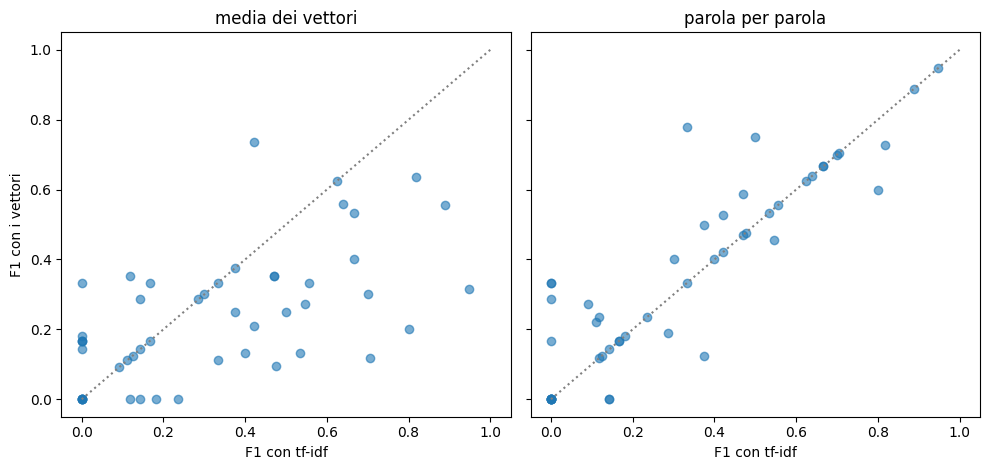

media dei vettori: meglio di tf-idf in 10 query, uguale in 16, peggio in 24
parola per parola: meglio di tf-idf in 13 query, uguale in 30, peggio in 7


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, name in zip(axes, ['media dei vettori', 'parola per parola']):
    ax.scatter(results['tf-idf']['f1'], results[name]['f1'], alpha=0.6)
    ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
    ax.set_xlabel('F1 con tf-idf')
    ax.set_title(name)
axes[0].set_ylabel('F1 con i vettori')
plt.tight_layout()
plt.show()

for name in ['media dei vettori', 'parola per parola']:
    diff = results[name]['f1'] - results['tf-idf']['f1']
    print(f"{name}: meglio di tf-idf in {int((diff > 0).sum())} query, uguale in {int((diff == 0).sum())}, peggio in {int((diff < 0).sum())}")

## Un momento di riflessione

- Nella media delle 50 query, quale motore è migliore? Di quanto? Basta questa differenza per decidere?
- Nei grafici, quante query stanno sopra la diagonale? Il motore parola per parola è meglio di tf-idf quasi sempre, o solo in alcune query?
- Il confronto con la media dei vettori mostra che usare gli embedding non basta: conta *come*. Che cosa cambia tra le due versioni?
- Nel punteggio, che ruolo ha l'idf? Che cosa succederebbe a una query con *e* e *il*?

## Una query che tf-idf non può risolvere

In L09 la query «città tropicali in Asia» aveva un F1 vicino a zero: nessun testo contiene la parola *Asia* vicino a *Singapore*. Vediamo che cosa fa il motore con i vettori, e con quali parole del testo ha confrontato ciascuna parola della query, per il testo primo in classifica e per quello di Singapore.

In [12]:
q_geo = 'città tropicali in Asia'
print('rilevanti:', sorted(relevant[q_geo]))
top = pd.concat({'tf-idf': rank_tfidf(q_geo).head(8).reset_index().set_axis(['città', 'punteggio'], axis=1),
                 'parola per parola': rank_soft(q_geo).head(8).reset_index().set_axis(['città', 'punteggio'], axis=1)}, axis=1).round(3)
top['rilevante (tf-idf)'] = ['sì' if c in relevant[q_geo] else 'no' for c in top[('tf-idf', 'città')]]
top['rilevante (parola per parola)'] = ['sì' if c in relevant[q_geo] else 'no' for c in top[('parola per parola', 'città')]]
print(top.to_string())

best = rank_soft(q_geo).index[0]
print(f'\nPer ogni parola della query, la parola più simile nel testo di {best} (primo in classifica) e di Singapore:')
pd.concat({best: word_matches(q_geo, best), 'Singapore': word_matches(q_geo, 'Singapore')}, axis=1)

rilevanti: ['Bangkok', 'Calcutta', 'Colombo', 'Giacarta', 'Ho Chi Minh', 'Manila', 'Mumbai', 'Singapore']
           tf-idf           parola per parola           rilevante (tf-idf) rilevante (parola per parola)
            città punteggio             città punteggio                                                 
0  Città del Capo     0.208             Belém     0.567                 no                            no
1         Jakutsk     0.208         Singapore     0.545                 no                            sì
2   Dar es Salaam     0.172         Vancouver     0.492                 no                            no
3         Ushuaia     0.135           Bangkok     0.486                 no                            sì
4         Vorkuta     0.135            Napoli     0.482                 no                            no
5        Cagliari     0.133           Magadan     0.477                 no                            no
6          Assuan     0.130            Londra     0.47

Belém                                           \
  parola della query parola più simile nel testo coseno   idf   
0          tropicali                  abbondanti   0.63  4.61   
1               asia                   amazzonia   0.51  4.61   

           Singapore                                           
  parola della query parola più simile nel testo coseno   idf  
0          tropicali                  abbondanti   0.63  4.61  
1               asia                   singapore   0.46  4.61

## Un momento di riflessione

- Quali città restituiscono i due motori? Quante sono rilevanti?
- Il testo di *Singapore* contiene la parola *Asia*? Con quale parola il motore l'ha confrontata? E nel testo primo in classifica, che non è asiatico?
- Dove ha preso il modello l'informazione che Singapore è in Asia? Che cosa ci dice sui testi su cui è stato allenato?
- Il motore con i vettori è meno trasparente di tf-idf: possiamo dire esattamente perché ha scelto un testo? Con la tabella delle parole più simili possiamo ricostruirlo?
- Se il modello sbagliasse, per esempio mettendo una città tropicale africana tra le asiatiche, che cosa potremmo concludere sul modello?

## Provate voi: query libere

Scrivete una query nella variabile `free_query` e confrontate i due motori. Provate query con parole che non compaiono nei testi, per esempio sinonimi o descrizioni indirette («afa», «gelo», «nebbia fitta»).

In [13]:
free_query = 'afa e zanzare'

ignored = [w for w in alpha_tokens(free_query) if w not in column]
if ignored:
    print('parole che tf-idf non può usare (fuori dal vocabolario dei testi):', ignored)


def show(rank, k=10):
    r = rank(free_query).head(k)
    return pd.DataFrame({'città': r.index, 'punteggio': r.round(3).values, 'clima': climate[r.index].values}, index=range(1, k + 1))


pd.concat({'tf-idf': show(rank_tfidf), 'parola per parola': show(rank_soft)}, axis=1)

parole che tf-idf non può usare (fuori dal vocabolario dei testi): ['zanzare']


tf-idf                      parola per parola                     
         città punteggio      clima             città punteggio      clima
1      Bangkok     0.306  tropicale           Bangkok     0.672  tropicale
2    Singapore     0.000  tropicale       Kuwait City     0.494  desertico
3    Amsterdam     0.000  temperato            Assuan     0.489  desertico
4      Toronto     0.000  temperato             Dubai     0.473  desertico
5      Chicago     0.000  temperato             Riyad     0.473  desertico
6   Wellington     0.000  temperato          Ojmjakon     0.472     polare
7    Vancouver     0.000  temperato            Mumbai     0.463  tropicale
8      Seattle     0.000  temperato            Manaus     0.463  tropicale
9    Bruxelles     0.000  temperato             Lagos     0.463  tropicale
10    Varsavia     0.000  temperato          Kinshasa     0.463  tropicale

## B. Un lessico tematico per leggere un corpus

Per le prossime sezioni usiamo i discorsi dell'**Assemblea Costituente** (1946-48), nel corpus degli atti parlamentari. Ogni discorso ha un oratore e un testo. Escludiamo il presidente, i segretari che leggono gli appelli e le interruzioni anonime, che sono formule e non discorsi.

Analizzare tutto il corpus richiederebbe molto tempo, quindi estraiamo un **campione casuale** di discorsi (con almeno 60 parole, tagliati alle prime 250) e li passiamo a spaCy per ottenere il **lemma** e la categoria grammaticale di ogni parola. I lemmi riducono *lavoratore*, *lavoratori*, *lavoratrici* a una forma sola. Facciamo lo stesso per i discorsi della Camera tra il 1923 e il 1938, che ci serviranno nella parte C. Il risultato viene salvato su disco e riusato.

In [14]:
PARLAMENTO = '/Users/Flint/Data/parlamento/Dati Parlamento/'


def read_speeches(files):
    speeches = []
    for path in files:
        current = None
        with open(path) as f:
            records = json.load(f)
        for r in records:
            speaker = r['speaker']
            if r['type'] != 'text' or speaker in ('none', 'unknown') or speaker.startswith(('PRESIDENTE', 'VOCI')) or 'SEGRETARIO' in speaker:
                current = None
                continue
            if current and current['speaker'] == speaker:
                current['text'] += ' ' + r['content']
            else:
                current = {'speaker': speaker.split(',')[0], 'text': r['content']}
                speeches.append(current)
    return speeches


def build_sample(name, files, n=3000, seed=0):
    path = f'data/cache_{name}.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    speeches = [s for s in read_speeches(files) if len(s['text'].split()) >= 60]
    total = len(speeches)
    sample = random.Random(seed).sample(speeches, n)
    texts = [' '.join(s['text'].split()[:250]) for s in sample]
    docs = nlp.pipe(texts, batch_size=64, disable=['parser', 'ner'])
    result = {'total': total, 'speeches': [{'speaker': s['speaker'], 'text': t, 'tokens': [(w.lemma_.lower(), w.pos_) for w in d if w.is_alpha]}
                                           for s, t, d in zip(sample, texts, docs)]}
    with open(path, 'wb') as f:
        pickle.dump(result, f)
    return result


constituent_files = sorted(f for f in os.listdir(PARLAMENTO) if 'scostituente' in f)
constituent = build_sample('costituente', [PARLAMENTO + f for f in constituent_files])
regime_files = sorted(f for f in os.listdir(PARLAMENTO) if '1923' <= f[:4] <= '1938')
regime = build_sample('regime', [PARLAMENTO + f for f in regime_files])

sample_c = constituent['speeches']
sample_r = regime['speeches']
print(len(constituent_files), 'sedute,', constituent['total'], 'discorsi di almeno 60 parole, campione:', len(sample_c))
print('parole nel campione:', sum(len(s['tokens']) for s in sample_c))
print('(il campione della Camera 1923-38 è pronto: lo useremo nella parte C)')
print('\noratori più presenti nel campione:')
print(pd.Series([s['speaker'] for s in sample_c]).value_counts().head(8).to_string())
print('\nUn discorso a caso:')
example = sample_c[7]
print(example['speaker'], '-', example['text'][:400], '...')
print(example['tokens'][:12])

375 sedute, 22722 discorsi di almeno 60 parole, campione: 3000
parole nel campione: 469113
(il campione della Camera 1923-38 è pronto: lo useremo nella parte C)

oratori più presenti nel campione:
RUINI         125
DE GASPERI     96
EINAUDI        59
NITTI          55
PELLA          53
SCELBA         50
LUSSU          49
TOGLIATTI      49

Un discorso a caso:
EINAUDI - Insieme con gli altri, insorse a difesa del governo borbonico, insorse a difesa della sua amministrazione, amministrazione che era in verità un'ottima amministrazione, Agostino Magliani. Egli dimostrò, in un opuscolo celebre, che a Napoli le imposte erano mitissime, le più miti che si conoscessero in Italia; che il debito pubblico, per testa di abitante, era il più tenue che ci fosse al mondo, e c ...
[('insieme', 'ADV'), ('con', 'ADP'), ('il', 'DET'), ('altro', 'PRON'), ('insorgere', 'VERB'), ('a', 'ADP'), ('difesa', 'NOUN'), ('di il', 'ADP'), ('governo', 'NOUN'), ('borbonico', 'ADJ'), ('insorgere', 'VERB'), ('a', 'ADP'

## Un momento di riflessione

- Perché abbiamo tolto il presidente e i segretari? Che cosa sarebbe successo ai nostri risultati se li avessimo lasciati?
- Il campione è casuale, ma contiene più discorsi di alcuni oratori che di altri. Che cosa significa per ciò che troveremo?
- Guardate i lemmi del discorso a caso. Quali parole sono cambiate rispetto al testo? Che informazione abbiamo ottenuto in più, la categoria grammaticale, e a che cosa servirà?
- Ogni scelta fatta (60 parole, 250 parole, 3000 discorsi) cambia il campione. Come potremmo controllare che i risultati non dipendano da queste scelte?

## Pulire i vettori

Quando cerchiamo i vicini di una parola, spesso vincono parole che le assomigliano per forma, non per significato: i vicini di *regione* sono quasi tutte parole in *-zione*. È una componente comune a molte parole che i vettori contengono, legata alla frequenza e alla morfologia.

Un rimedio semplice è togliere dai vettori la media e le prime cinque direzioni principali, calcolate sulle parole dei nostri testi: quello che hanno in comune quasi tutte. Ci limitiamo ai nomi e agli aggettivi, che portano il tema, e teniamo le parole con almeno 20 occorrenze.

In [15]:
def content_lemmas(sample, pos=('NOUN', 'ADJ')):
    return [[l for l, p in s['tokens'] if p in pos and len(l) > 2 and l not in stop_words and nlp.vocab.has_vector(l)] for s in sample]


lemmas_c, lemmas_r = content_lemmas(sample_c), content_lemmas(sample_r)
freq_c = collections.Counter(w for d in lemmas_c for w in d)
freq_r = collections.Counter(w for d in lemmas_r for w in d)
vocab_c = [w for w, c in freq_c.items() if c >= 20]
vocab_both = [w for w, c in (freq_c + freq_r).items() if c >= 20]

raw = np.array([vec(w) for w in vocab_both])
mean_all = raw.mean(axis=0)
_, _, Vt = np.linalg.svd(raw - mean_all, full_matrices=False)
common = Vt[:5]


def clean(v):
    x = v - mean_all
    x = x - common.T @ (common @ x)
    return x / np.linalg.norm(x)


clean_c = np.array([clean(vec(w)) for w in vocab_c])


def neighbors_in(word, vocab, matrix, k=8, cleaned=True):
    q = clean(vec(word)) if cleaned else unit(vec(word))
    raw_matrix = matrix if cleaned else np.array([unit(vec(w)) for w in vocab])
    return [vocab[i] for i in np.argsort(-(raw_matrix @ q)) if vocab[i] != word][:k]


probe = ['regione', 'scuola', 'lavoro', 'chiesa']
print(len(vocab_c), 'parole (nomi e aggettivi) con almeno 20 occorrenze nel campione')
pd.concat({'vettori originali': pd.DataFrame({w: neighbors_in(w, vocab_c, clean_c, 6, cleaned=False) for w in probe}).T,
           'vettori puliti': pd.DataFrame({w: neighbors_in(w, vocab_c, clean_c, 6) for w in probe}).T}, axis=1)

1108 parole (nomi e aggettivi) con almeno 20 occorrenze nel campione


vettori originali                                               \
                        0               1            2               3   
regione           nazione  circoscrizione  popolazione  confederazione   
scuola         scolastico      insegnante   università   universitario   
lavoro         lavoratore   professionale    personale         impegno   
chiesa           edificio      abitazione    religione        comunità   

                                     vettori puliti              \
                    4              5              0           1   
regione   meridionale      provincia        nazione   provincia   
scuola     istruzione     educazione     scolastico  insegnante   
lavoro   insegnamento  licenziamento     lavoratore     impegno   
chiesa         piazza       famiglia       edificio  abitazione   

                                                                     
                     2              3               4             5  
regione           zona    meridionale  circoscrizione     regionale  
scuola      educazione  universitario      istruzione  insegnamento  
lavoro   professionale        salario     occupazione       ricerca  
chiesa       religioso      cristiano          piazza     struttura

## Un momento di riflessione

- Quali dei due elenchi di vicini dà un'idea più giusta del tema? Perché?
- Abbiamo tolto cinque direzioni. Che cosa succederebbe togliendone trenta? Come ci accorgeremmo di averne tolte troppe?
- Cercare i vicini solo tra le parole che compaiono nel campione (e non tra le 50 mila) che cosa cambia? Quali parole non vedremo mai?
- I vettori sono nati da testi contemporanei, i nostri discorsi hanno ottant'anni. Quali parole potrebbero avere vicini diversi nel 1947?

## Quali temi emergono

Prima di decidere noi di che cosa cercare, lasciamo che siano i dati a suggerire dei temi. Prendiamo i 700 nomi più frequenti del campione, li raggruppiamo con il k-means (dodici gruppi) sui vettori puliti e guardiamo, per ciascun gruppo, le parole più vicine al suo centro. Nella mappa disegniamo le dieci parole più centrali di ogni gruppo.

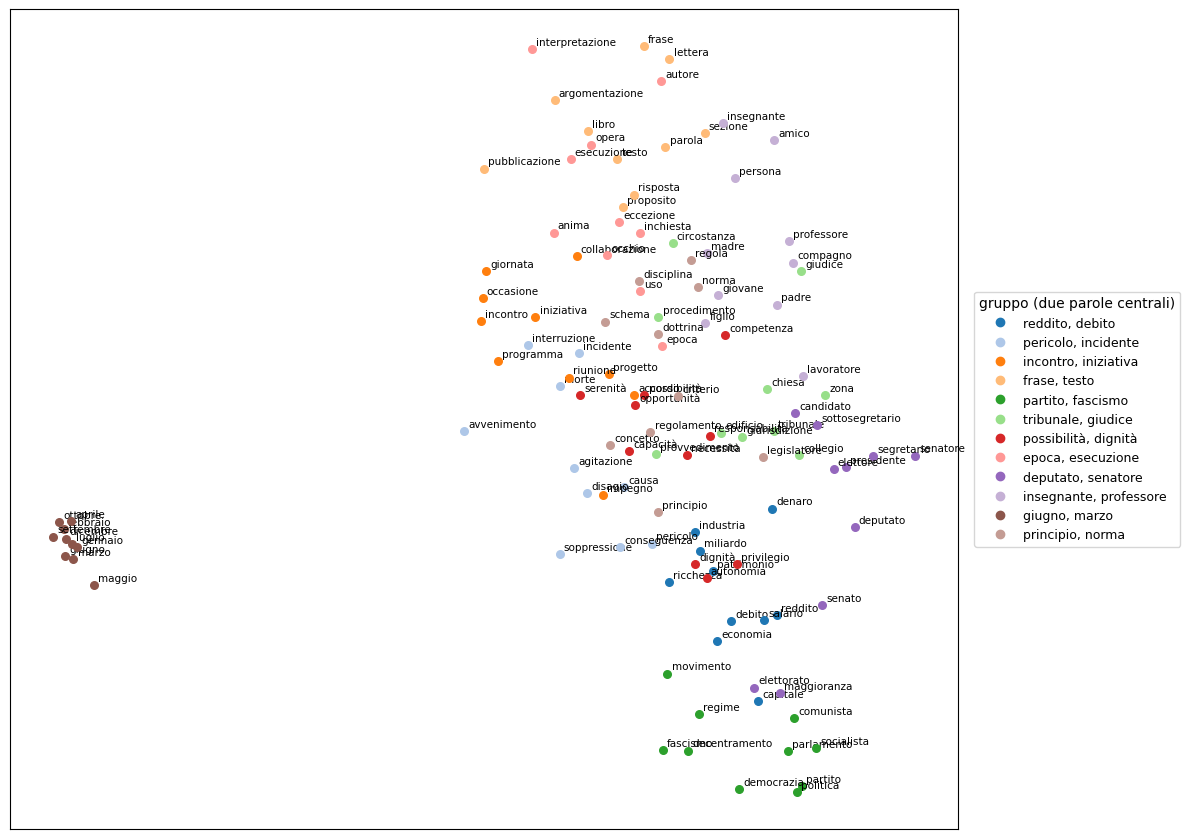

,parole,dimensione
0,"reddito, debito, economia, denaro, miliardo, r...",78
1,"pericolo, incidente, causa, interruzione, mort...",71
2,"incontro, iniziativa, impegno, collaborazione,...",56
3,"frase, testo, argomentazione, lettera, libro, ...",81
4,"partito, fascismo, movimento, comunista, parla...",54
5,"tribunale, giudice, procedimento, zona, provve...",58
6,"possibilità, dignità, capacità, opportunità, r...",56
7,"epoca, esecuzione, interpretazione, uso, occhi...",72
8,"deputato, senatore, presidente, senato, candid...",48
9,"insegnante, professore, padre, compagno, amico...",57


In [16]:
nouns_c = content_lemmas(sample_c, ('NOUN',))
noun_freq = collections.Counter(w for d in nouns_c for w in d)
top_nouns = [w for w, c in noun_freq.most_common(700) if c >= 15]
Z = np.array([clean(vec(w)) for w in top_nouns])

K = 12
km = KMeans(K, n_init=10, random_state=0).fit(Z)
central = {k: sorted([i for i in range(len(top_nouns)) if km.labels_[i] == k], key=lambda i: -(Z[i] @ km.cluster_centers_[k])) for k in range(K)}

cmap = plt.get_cmap('tab20')
shown = [i for k in range(K) for i in central[k][:10]]
P = pca2(Z[shown])
fig, ax = plt.subplots(figsize=(12, 8.5))
for (x, y), i in zip(P, shown):
    ax.scatter(x, y, color=cmap(km.labels_[i]), s=30, zorder=3)
    ax.annotate(top_nouns[i], (x, y), fontsize=7.5, xytext=(3, 3), textcoords='offset points')
handles = [Line2D([], [], marker='o', color=cmap(k), linestyle='', label=', '.join(top_nouns[i] for i in central[k][:2])) for k in range(K)]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=9, title='gruppo (due parole centrali)')
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

pd.DataFrame({'parole': {k: ', '.join(top_nouns[i] for i in central[k][:10]) for k in range(K)},
              'dimensione': {k: len(central[k]) for k in range(K)}})

## Un momento di riflessione

- Quali gruppi corrispondono a temi che riconoscete? Come li chiamereste?
- Ci sono gruppi che non sono temi: raccolgono parole usate in modo simile (mesi, parole del dibattito) più che argomenti? Che cosa significa?
- Il k-means ha richiesto di scegliere il numero di gruppi. Con otto o venti gruppi, i temi sarebbero gli stessi?
- Una parola appartiene a un solo gruppo. Quali parole potrebbero stare in due?
- Questi temi sono quelli del corpus o quelli del modello? Come potremmo distinguere?

## Un lessico a partire da poche parole

Un lessico tematico è una lista di parole che, nel corpus, rimandano allo stesso tema. Lo costruiamo a partire da poche parole **seme**, scelte da noi: i vettori propongono altre parole vicine al centro dei semi, tra quelle che compaiono davvero nel corpus.

In [17]:
seeds = {
    'lavoro': ['lavoro', 'operaio', 'salario', 'sindacato', 'sciopero'],
    'religione': ['chiesa', 'religione', 'clero', 'concordato', 'fede'],
    'scuola': ['scuola', 'istruzione', 'insegnante', 'università', 'studio'],
    'territorio': ['regione', 'autonomia', 'provincia', 'comune', 'decentramento'],
    'giustizia': ['magistrato', 'giudice', 'tribunale', 'processo', 'giustizia'],
}


def expand(seed_words, k=20):
    center = unit(np.mean([clean(vec(s)) for s in seed_words], axis=0))
    return [vocab_c[i] for i in np.argsort(-(clean_c @ center)) if vocab_c[i] not in seed_words][:k]


candidates = pd.DataFrame({theme: expand(ws) for theme, ws in seeds.items()}).rename(index=lambda i: i + 1)
candidates

,lavoro,religione,scuola,territorio,giustizia
1,sindacale,cristiano,universitario,capoluogo,magistratura
2,lavoratore,religioso,insegnamento,territorio,procedimento
3,stipendio,cattolico,educazione,territoriale,giudiziario
4,disoccupazione,dottrina,professore,provinciale,cassazione
5,licenziamento,sacro,scolastico,circoscrizione,penale
6,occupazione,spirituale,istituto,zona,corte
7,socialista,comunità,cattedra,comunità,sentenza
8,disoccupato,monarchia,formazione,cittadino,polizia
9,contadino,canone,professionale,meridionale,giudizio
10,reddito,lateranense,elementare,cittadinanza,giurisdizionale


## Un momento di riflessione

- Per ogni tema, quali delle parole proposte tenereste? Quali scarterebbe uno storico? Che cosa le ha fatte proporre?
- Compaiono parole che stanno in un tema ma che nessuno avrebbe pensato di aggiungere? Sono una scoperta o un errore?
- Il lessico dipende dalle parole seme. Con altri semi, per esempio con *sciopero* soltanto, che cosa cambierebbe?
- Chi decide quali parole entrano nel lessico: la macchina o chi lo costruisce? Con quale criterio?

## Chi parla di cosa

Il lessico è uno strumento di misura. Per ciascun discorso calcoliamo la **quota di parole** che appartengono al lessico di un tema, poi facciamo la media per oratore. Il lessico finale è fatto dei semi più le parole che abbiamo deciso di tenere: scrivetele nella cella, aggiungete o togliete a piacere.

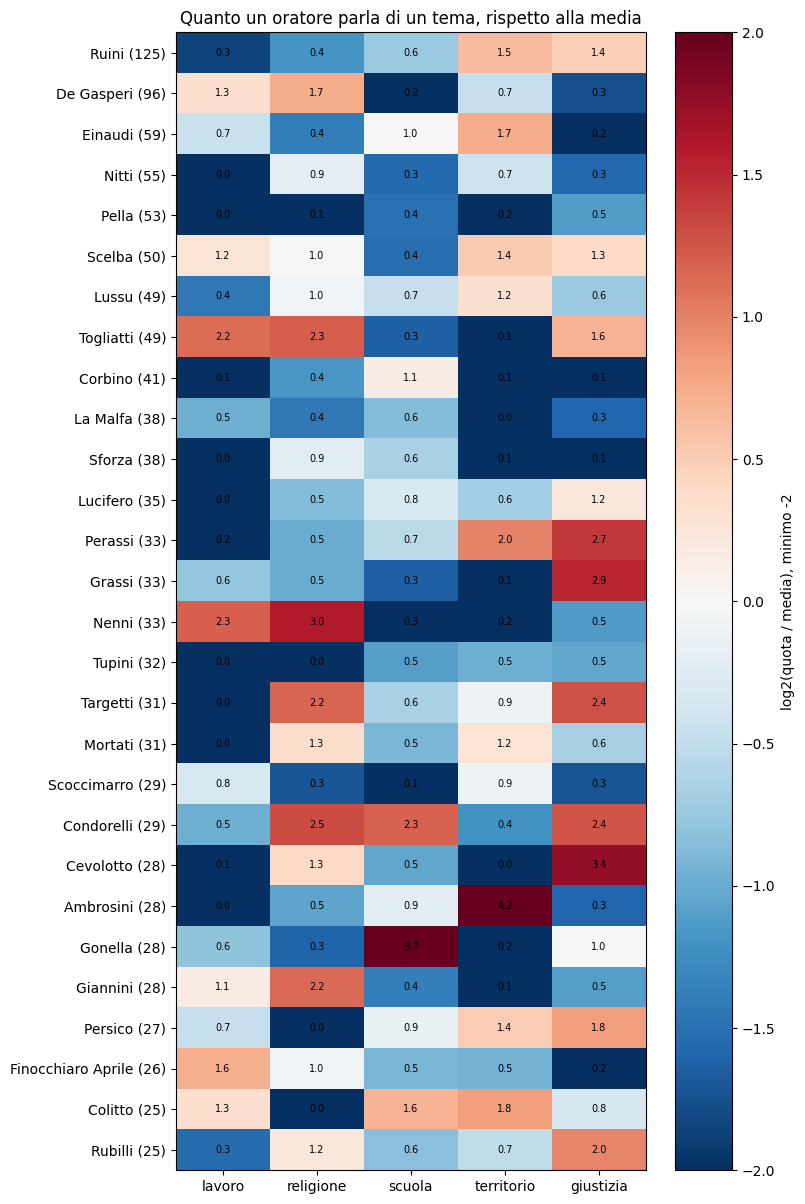

In [18]:
keep = {
    'lavoro': ['sindacale', 'lavoratore', 'stipendio', 'disoccupazione', 'licenziamento', 'occupazione', 'disoccupato', 'contadino', 'agricolo', 'produttivo'],
    'religione': ['cristiano', 'religioso', 'cattolico', 'dottrina', 'sacro', 'spirituale', 'canone', 'lateranense'],
    'scuola': ['universitario', 'insegnamento', 'educazione', 'professore', 'scolastico', 'istituto', 'cattedra', 'formazione', 'elementare', 'facoltà', 'aula'],
    'territorio': ['capoluogo', 'territorio', 'territoriale', 'provinciale', 'circoscrizione', 'comunale', 'regionale', 'abitante', 'popolazione'],
    'giustizia': ['magistratura', 'procedimento', 'giudiziario', 'cassazione', 'penale', 'corte', 'sentenza', 'giudizio', 'giurisdizionale', 'reato', 'avvocato', 'delitto', 'giurista'],
}
themes = {t: set(seeds[t]) | set(keep[t]) for t in seeds}


def theme_share(lemmas, lexicon_set):
    return np.array([sum(w in lexicon_set for w in d) / max(len(d), 1) for d in lemmas])


speaker_of = [s['speaker'] for s in sample_c]
shares = pd.DataFrame({t: theme_share(lemmas_c, lx) for t, lx in themes.items()})
shares['oratore'] = speaker_of
by_speaker = shares.groupby('oratore').agg(['mean'])
by_speaker.columns = [c[0] for c in by_speaker.columns]
count = pd.Series(speaker_of).value_counts()
top_speakers = count[count >= 25].index
table = by_speaker.loc[top_speakers]
relative = table / shares.drop(columns='oratore').mean()

fig, ax = plt.subplots(figsize=(8, 0.38 * len(table) + 1.5))
im = ax.imshow(np.log2(np.maximum(relative.values, 0.25)), cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(table.columns)))
ax.set_xticklabels(table.columns)
ax.set_yticks(range(len(table)))
ax.set_yticklabels([f'{s.title()} ({count[s]})' for s in table.index])
for i in range(len(table)):
    for j in range(len(table.columns)):
        ax.text(j, i, f'{relative.values[i, j]:.1f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, label='log2(quota / media), minimo -2')
ax.set_title('Quanto un oratore parla di un tema, rispetto alla media')
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Quali oratori emergono per ciascun tema? Corrisponde a quello che sapete di loro?
- Alcuni oratori hanno pochi discorsi nel campione. Quanto ci possiamo fidare delle loro medie?
- Che cosa misura davvero il numero nella tabella: l'interesse dell'oratore per il tema o la presenza di alcune parole? Una parola del lessico può essere usata in un discorso su un altro tema?
- Se un oratore non usa mai le parole del lessico ma parla di lavoro con altre parole, che cosa succede alla misura?

## Leggere i discorsi che il lessico segnala

Una misura va sempre controllata leggendo. Per ciascun tema mostriamo il discorso del campione con la quota più alta di parole del lessico.

In [19]:
for theme in themes:
    i = int(np.argmax(theme_share(lemmas_c, themes[theme])))
    print(f"[{theme}] {sample_c[i]['speaker'].title()}: {sample_c[i]['text'][:420]} ...")
    print()

[lavoro] Di Vittorio: Perché non protestate contro gli industriali che riducono alla fame diecine di migliaia di operai? Potrei dimostrare con delle statistiche che nelle provincie dove v'è stato o vi può essere uno sciopero vittorioso, gli agrari applicano il lodo De Gasperi; mentre dove essi pensano che scioperi non ve ne possano essere, li si rifiutano apertamente di applicarlo. Cosa deve fare l'organizzazione operaia? Rinunziare alla  ...

[religione] Calosso: Ora, io vorrei votare questo emendamento proposto dai democratici cristiani e, se l'onorevole Laconi si accordasse e lasciasse ai democratici cristiani la formulazione dell'emendamento, io ne sarei lieto, e questa sarebbe una bella manifestazione, specialmente per voi (Accenna al centro) di fronte al Paese. Sarebbe, effettivamente, un inizio di quella pacificazione religiosa che voi avete avuto al balzo e che non ave ...

[scuola] Gonella: Di coloro, sui quali ho chiesto il parere alle facoltà, solo due sono stati da me confe

## Un momento di riflessione

- Il discorso che il lessico segnala parla davvero del tema? Che cosa lo ha fatto salire in classifica?
- Il discorso più alto è anche il più rappresentativo? Che cosa dice sulla differenza tra quota alta e discorso migliore?
- Leggere 5 discorsi è un controllo sufficiente? Quanti ne servirebbero? Di quali discorsi?
- Un lessico costruito con i vettori ha cercato parole simili ai semi. Poteva scoprire un tema nuovo? E un uso nuovo di una parola?

## C. Due lessici a confronto: Costituenti e regime

Con lo stesso strumento possiamo confrontare due corpora. Prendiamo, accanto alla Costituente, i discorsi della Camera dei deputati tra il 1923 e il 1938. Il procedimento è lo stesso: stesso campione casuale di 3000 discorsi, stessi filtri, stesso modello.

Un vantaggio dei vettori già allenati è che i due corpora vivono **nello stesso spazio**: non ci sono mappe diverse da allineare, come nel notebook precedente.

In [20]:
print(pd.DataFrame({'sedute': [len(constituent_files), len(regime_files)],
                    'discorsi (>= 60 parole)': [constituent['total'], regime['total']],
                    'discorsi nel campione': [len(sample_c), len(sample_r)],
                    'nomi e aggettivi nel campione': [sum(freq_c.values()), sum(freq_r.values())]},
                   index=['Costituente 1946-48', 'Camera 1923-38']).to_string())
print('\noratori più presenti nel campione del regime:')
print(pd.Series([s['speaker'] for s in sample_r]).value_counts().head(8).to_string())

                     sedute  discorsi (>= 60 parole)  discorsi nel campione  nomi e aggettivi nel campione
Costituente 1946-48     375                    22722                   3000                         124776
Camera 1923-38          684                    32553                   3000                         132306

oratori più presenti nel campione del regime:
ROCCO        78
MUSSOLINI    75
ACERBO       48
FEDERZONI    45
CIANO        36
SOLMI        32
BELLUZZO     31
BOTTAI       31


## Un momento di riflessione

- I due campioni hanno la stessa dimensione ma sono stati estratti da corpora di dimensione diversa. Che conseguenze ha?
- La Camera del 1923-38 non è più una sede di dibattito libero. Che cosa possiamo aspettarci dal tipo di discorsi?
- Quali oratori compaiono? Che ruoli hanno?
- Confrontare due corpora richiede che siano confrontabili. Che cosa dovremmo controllare prima di fidarci del confronto?

## Le parole che distinguono

Per ogni parola calcoliamo quanto è più frequente in un corpus che nell'altro, con il logaritmo del rapporto tra le due frequenze relative (con un piccolo aggiustamento per le parole rare). Teniamo solo le parole con almeno 25 occorrenze in tutto e togliamo i cognomi dei deputati.

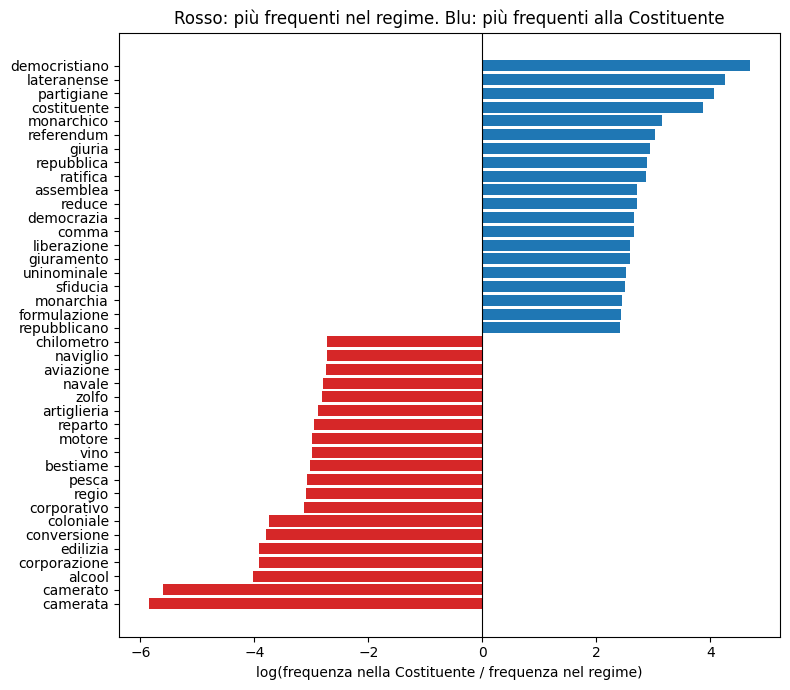

In [21]:
speaker_names = {w.lower() for s in sample_c + sample_r for w in s['speaker'].split()}
total_c, total_r = sum(freq_c.values()), sum(freq_r.values())
candidates_words = [w for w in set(freq_c) | set(freq_r) if freq_c[w] + freq_r[w] >= 25 and w not in speaker_names]
log_ratio = pd.Series({w: np.log((freq_c[w] + 0.5) / total_c) - np.log((freq_r[w] + 0.5) / total_r) for w in candidates_words}).sort_values()

n = 20
fig, ax = plt.subplots(figsize=(8, 7))
selection = pd.concat([log_ratio.head(n), log_ratio.tail(n)])
ax.barh(selection.index, selection.values, color=['tab:red'] * n + ['tab:blue'] * n)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('log(frequenza nella Costituente / frequenza nel regime)')
ax.set_title('Rosso: più frequenti nel regime. Blu: più frequenti alla Costituente')
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Le parole più caratteristiche di ciascun corpus raccontano la sua storia? Quali vi sorprendono?
- Alcune parole sono tipiche per ragioni di epoca o di istituzione, non per tema (*camerata*, *comma*, *emendamento*). Che differenza c'è tra un lessico di temi e un lessico di stile?
- Una parola poco frequente può avere un rapporto altissimo. Perché abbiamo imposto una soglia di 25 occorrenze?
- Questa lista parla di frequenze. Che cosa ci aggiungono i vettori, se li usiamo adesso?

## Dove stanno nello spazio

Mettiamo sulla stessa mappa le quaranta parole più caratteristiche per ciascun corpus, usando i vettori puliti. Il colore dice di quale corpus sono tipiche. Se le due liste fossero due vocabolari separati, vedremmo due nuvole; se si mescolano, vuol dire che i due corpora parlano degli stessi temi con parole diverse.

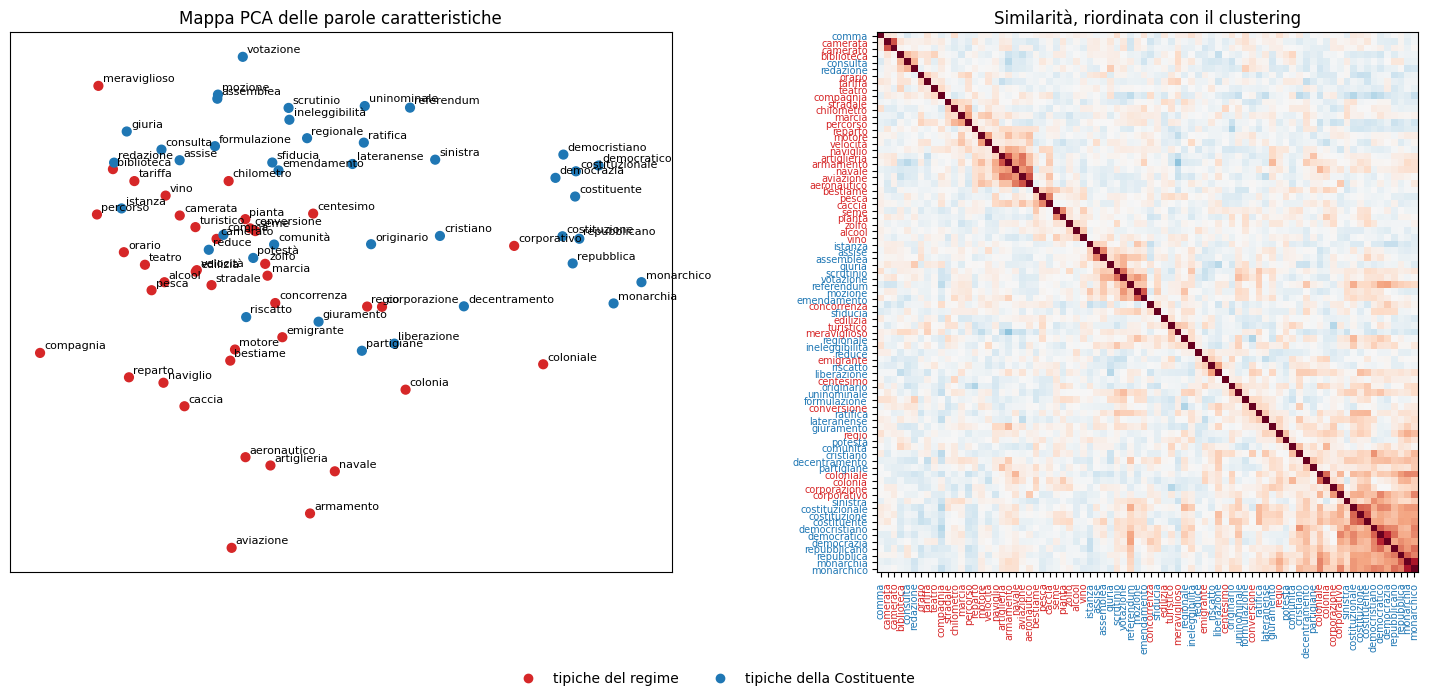

In [22]:
n = 40
words_r = list(log_ratio.head(n).index)
words_c = list(log_ratio.tail(n).index)
words_both = words_r + words_c
M = np.array([clean(vec(w)) for w in words_both])
colors_both = ['tab:red'] * n + ['tab:blue'] * n

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw_map(axes[0], pca2(M), words_both, colors_both, 'Mappa PCA delle parole caratteristiche', fontsize=8)
draw_similarity(axes[1], M, words_both, colors_both, 'Similarità, riordinata con il clustering')
handles = [Line2D([], [], marker='o', color=c, linestyle='', label=l) for c, l in [('tab:red', 'tipiche del regime'), ('tab:blue', 'tipiche della Costituente')]]
fig.legend(handles=handles, loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Un momento di riflessione

- I due colori sono separati o mescolati? Che cosa ci dice sul rapporto tra i due lessici?
- Ci sono gruppi di parole di colori diversi vicinissime? Come leggiamo quella vicinanza: stesso tema, uso diverso?
- Ci sono gruppi di un solo colore? Che tema rappresentano?
- Una parola come *regime* o *razza* ha vicini nel modello contemporaneo che sono stati costruiti molto dopo il 1938. Che conseguenze ha sul nostro confronto?

## I temi dei due corpora

Raggruppiamo i vettori dei nomi più frequenti dei due corpora insieme, in dieci temi, e per ciascun tema confrontiamo il peso nei due corpora. Poiché lo spazio è lo stesso, il gruppo è lo stesso per entrambi.

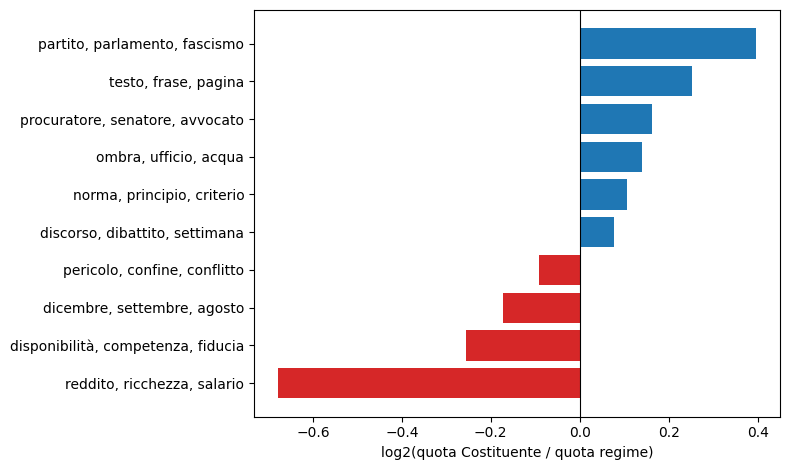

,parole,quota Costituente,quota regime,log2 rapporto
0,"reddito, ricchezza, salario, denaro, debito, p...",0.076,0.122,-0.678
1,"disponibilità, competenza, fiducia, soddisfazi...",0.095,0.113,-0.255
2,"dicembre, settembre, agosto, novembre, maggio,...",0.045,0.051,-0.173
3,"pericolo, confine, conflitto, minaccia, distru...",0.104,0.111,-0.092
4,"discorso, dibattito, settimana, evento, giorna...",0.113,0.107,0.077
5,"norma, principio, criterio, statuto, concetto,...",0.139,0.129,0.107
6,"ombra, ufficio, acqua, anima, idea, occhio, an...",0.144,0.130,0.139
7,"procuratore, senatore, avvocato, funzionario, ...",0.088,0.079,0.162
8,"testo, frase, pagina, libro, spiegazione, tabe...",0.113,0.095,0.253
9,"partito, parlamento, fascismo, democrazia, com...",0.083,0.063,0.397


In [23]:
noun_r = collections.Counter(w for d in content_lemmas(sample_r, ('NOUN',)) for w in d)
joint = noun_freq + noun_r
joint_words = [w for w, c in joint.most_common(1200) if c >= 15 and w not in speaker_names][:900]
Zj = np.array([clean(vec(w)) for w in joint_words])
K = 10
kmj = KMeans(K, n_init=10, random_state=0).fit(Zj)

rows = []
for k in range(K):
    ids = [i for i in range(len(joint_words)) if kmj.labels_[i] == k]
    ids = sorted(ids, key=lambda i: -(Zj[i] @ kmj.cluster_centers_[k]))
    share_c = sum(noun_freq[joint_words[i]] for i in ids) / sum(noun_freq[w] for w in joint_words)
    share_r = sum(noun_r[joint_words[i]] for i in ids) / sum(noun_r[w] for w in joint_words)
    rows.append({'parole': ', '.join(joint_words[i] for i in ids[:9]), 'quota Costituente': share_c, 'quota regime': share_r,
                 'log2 rapporto': np.log2(share_c / share_r)})
themes_table = pd.DataFrame(rows).sort_values('log2 rapporto')

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh([', '.join(p.split(', ')[:3]) for p in themes_table['parole']], themes_table['log2 rapporto'],
        color=['tab:red' if x < 0 else 'tab:blue' for x in themes_table['log2 rapporto']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('log2(quota Costituente / quota regime)')
plt.tight_layout()
plt.show()

themes_table.round(3).reset_index(drop=True)

## Un momento di riflessione

- Quali temi pesano di più nel regime? E alla Costituente? Corrispondono alle parole caratteristiche che abbiamo visto?
- Alcuni temi hanno un rapporto vicino a zero. Che cosa vuol dire: che i due corpora ne parlano allo stesso modo o allo stesso modo in quantità?
- Una quota di parole non è una quota di attenzione: un tema più frequente è più importante? Che cosa servirebbe per dirlo?
- Cambiando il numero di gruppi o il campione, i temi cambierebbero. Come potremmo valutare quanto il risultato sia stabile?

## Un asse tra due poli

Un **asse semantico** è la direzione che va dal centro di un gruppo di parole al centro di un altro. Scegliamo noi i due poli, per esempio *libertà, diritto, autonomia, democrazia* contro *autorità, ordine, disciplina, gerarchia*. Ogni parola ha una posizione lungo l'asse: la proiezione del suo vettore (il coseno con la direzione).

Prima di misurare i corpora guardiamo l'asse: quali parole del lessico dei discorsi stanno agli estremi?

In [24]:
axes_def = {
    'libertà - autorità': (['libertà', 'diritto', 'autonomia', 'democrazia'], ['autorità', 'ordine', 'disciplina', 'gerarchia']),
    'pace - guerra': (['pace', 'pacifico', 'pacifismo'], ['guerra', 'bellico', 'battaglia', 'armamento']),
    'individuo - collettività': (['individuo', 'persona', 'privato', 'iniziativa'], ['collettività', 'nazione', 'stato', 'corporazione']),
}


def axis(poles):
    pos, neg = poles
    return unit(np.mean([clean(vec(w)) for w in pos], axis=0) - np.mean([clean(vec(w)) for w in neg], axis=0))


axis_vectors = {name: axis(p) for name, p in axes_def.items()}
vocab_all = [w for w, c in (freq_c + freq_r).items() if c >= 20 and w not in speaker_names]
clean_all = np.array([clean(vec(w)) for w in vocab_all])

name = 'libertà - autorità'
proj = clean_all @ axis_vectors[name]
order = np.argsort(proj)
print(name)
print('verso il polo di sinistra:', ', '.join(vocab_all[i] for i in order[::-1][:14]))
print('verso il polo di destra:  ', ', '.join(vocab_all[i] for i in order[:14]))

libertà - autorità
verso il polo di sinistra: libertà, democrazia, autonomia, diritto, democratico, cittadinanza, indipendenza, sovranità, dignità, legalità, liberale, eguaglianza, solidarietà, socialista
verso il polo di destra:   ordine, tabella, ispettore, circostanza, raccomandazione, disciplina, composizione, trattazione, interrogante, elenco, schema, spiegazione, dottrina, severo


## Un momento di riflessione

- Le parole agli estremi dell'asse sono quelle che ci aspettavamo? Ce ne sono di inattese?
- Abbiamo scelto i poli noi: *libertà, diritto, autonomia, democrazia* da una parte, *autorità, ordine, disciplina, gerarchia* dall'altra. Quanto dipende l'asse da questa scelta?
- Un asse ha due estremi ma le parole possono stare nel mezzo per ragioni diverse: lontane da entrambi o vicine a entrambi. Possiamo distinguere?
- Che cosa significa che una parola sta «dalla parte» di *libertà*? Dice qualcosa sul significato della parola, o sui contesti in cui compare?

## Misurare i corpora lungo un asse

Per ciascun discorso calcoliamo la posizione media dei suoi nomi e aggettivi lungo l'asse; poi confrontiamo la media dei discorsi dei due corpora. Per capire quanto possiamo fidarci, ripetiamo il calcolo mille volte con campioni di discorsi estratti con ripetizione (**bootstrap**) e mostriamo l'intervallo che contiene il 95% dei risultati.

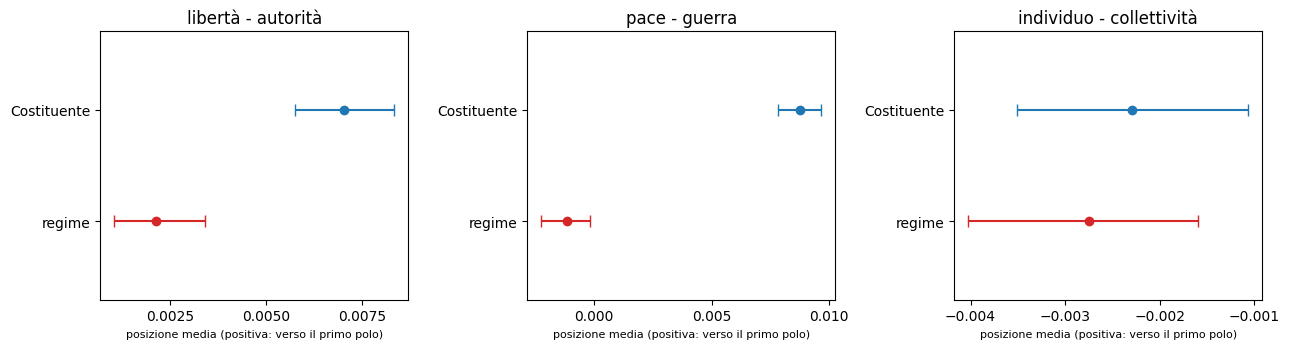

                          differenza (Cost. - regime)  effetto standardizzato
libertà - autorità                              0.005                   0.143
pace - guerra                                   0.010                   0.352
individuo - collettività                        0.000                   0.013

Quota delle parole del corpus che stanno tra le 30 più vicine a ciascun polo:
              Costituente (%)  regime (%)  rapporto Cost./regime
libertà                  2.86        1.32                   2.17
autorità                 1.48        1.05                   1.40
pace                     1.08        0.70                   1.53
guerra                   1.04        1.96                   0.53
individuo                1.31        1.05                   1.25
collettività             2.33        1.85                   1.26


In [25]:
clean_of = {w: clean(vec(w)) for w in set(freq_c) | set(freq_r)}


def speech_positions(lemmas, a):
    return np.array([np.mean([clean_of[w] @ a for w in d]) if d else np.nan for d in lemmas])


rng = np.random.default_rng(0)
summary = {}
for name, a in axis_vectors.items():
    pc, pr = speech_positions(lemmas_c, a), speech_positions(lemmas_r, a)
    pc, pr = pc[~np.isnan(pc)], pr[~np.isnan(pr)]
    boot = lambda x: np.array([rng.choice(x, len(x)).mean() for _ in range(1000)])
    bc, br = boot(pc), boot(pr)
    summary[name] = {'Costituente': (pc.mean(), *np.percentile(bc, [2.5, 97.5])), 'regime': (pr.mean(), *np.percentile(br, [2.5, 97.5])),
                     'differenza': pc.mean() - pr.mean(), 'effetto': (pc.mean() - pr.mean()) / np.sqrt((pc.var() + pr.var()) / 2)}

fig, axes_ = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, s) in zip(axes_, summary.items()):
    for k, (label, color) in enumerate([('regime', 'tab:red'), ('Costituente', 'tab:blue')]):
        m, lo, hi = s[label]
        ax.errorbar(m, k, xerr=[[m - lo], [hi - m]], fmt='o', color=color, capsize=4)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['regime', 'Costituente'])
    ax.set_ylim(-0.7, 1.7)
    ax.set_title(name)
    ax.set_xlabel('posizione media (positiva: verso il primo polo)', fontsize=8)
    ax.locator_params(axis='x', nbins=4)
plt.tight_layout()
plt.show()

print(pd.DataFrame({n: {'differenza (Cost. - regime)': s['differenza'], 'effetto standardizzato': s['effetto']} for n, s in summary.items()}).round(3).T)

tokens_c = [w for d in lemmas_c for w in d]
tokens_r = [w for d in lemmas_r for w in d]
pole_rows = {}
for name, a in axis_vectors.items():
    proj = pd.Series(clean_all @ a, index=vocab_all).sort_values()
    right, left = set(proj.index[:30]), set(proj.index[-30:])
    share = lambda tokens, group: sum(w in group for w in tokens) / len(tokens)
    left_label, right_label = name.split(' - ')
    pole_rows[f'{left_label}'] = {'Costituente': share(tokens_c, left), 'regime': share(tokens_r, left)}
    pole_rows[f'{right_label}'] = {'Costituente': share(tokens_c, right), 'regime': share(tokens_r, right)}
pole_table = pd.DataFrame(pole_rows).T
pole_table['rapporto Cost./regime'] = pole_table['Costituente'] / pole_table['regime']
print('\nQuota delle parole del corpus che stanno tra le 30 più vicine a ciascun polo:')
print((pole_table * [100, 100, 1]).round(2).rename(columns={'Costituente': 'Costituente (%)', 'regime': 'regime (%)'}).to_string())

## Un momento di riflessione

- Per ciascun asse, i due intervalli si sovrappongono? Che cosa vuol dire?
- La differenza tra le medie è piccola rispetto alla variabilità tra discorsi (l'effetto standardizzato). Che cosa significa, per un confronto tra due epoche?
- Il segno della differenza corrisponde a quello che ci aspettiamo dalla storia? Se non fosse così, a che cosa penseremmo prima: ai testi, al modello o alla scelta dei poli?
- Una media di mille parole per discorso, poi una media di mille discorsi: che cosa nasconde?
- La seconda tabella non misura la posizione media ma conta le parole che stanno vicine a ciascun polo. Dice la stessa cosa della prima? Quando è più informativa?
- Come costruiremmo un test che ci convinca che l'asse misura davvero «libertà - autorità» e non altro?

## Un asse da usare con cautela

L'ultimo asse è quello tra maschile e femminile: *uomo, maschio, padre, marito* contro *donna, femmina, madre, moglie*. Guardiamo quali parole il modello colloca da una parte e dall'altra, e dove mette alcuni mestieri.

parole dalla parte di «uomo»: esercito, impero, nemico, popolo, avversario, ordinamento, armamento, continente, regno, padre, fratello, predecessore, avvento, destino, ponte, potere
parole dalla parte di «donna»: donna, madre, moglie, specifico, maestra, speciale, delicato, meraviglioso, completo, didattico, proposto, consulta, rappresentativo, aggiuntivo, duplice, presentazione


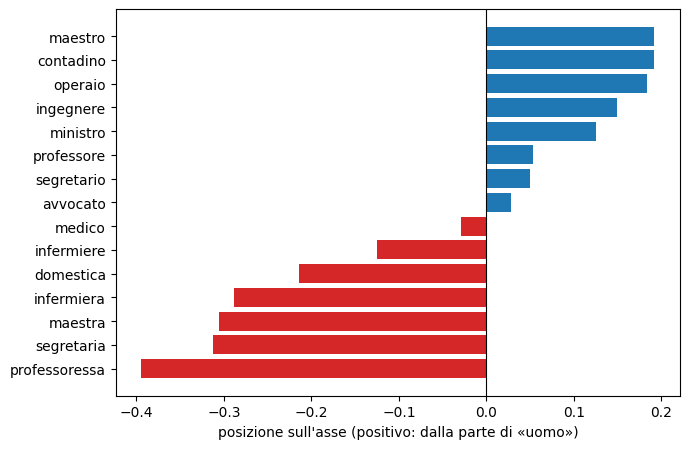

In [26]:
gender_axis = axis((['uomo', 'maschio', 'padre', 'marito'], ['donna', 'femmina', 'madre', 'moglie']))
proj = clean_all @ gender_axis
order = np.argsort(proj)
print('parole dalla parte di «uomo»:', ', '.join(vocab_all[i] for i in order[::-1][:16]))
print('parole dalla parte di «donna»:', ', '.join(vocab_all[i] for i in order[:16]))

jobs = ['ingegnere', 'avvocato', 'medico', 'ministro', 'operaio', 'contadino', 'maestro', 'maestra', 'infermiera', 'infermiere', 'segretaria', 'segretario', 'professore', 'professoressa', 'domestica']
positions = pd.Series({j: float(clean(vec(j)) @ gender_axis) for j in jobs}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(positions.index, positions.values, color=['tab:blue' if v > 0 else 'tab:red' for v in positions.values])
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('posizione sull\'asse (positivo: dalla parte di «uomo»)')
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Le parole dalla parte di «donna» sono tutte femminili per significato? Alcune sono femminili solo per genere grammaticale. Come potremmo separare le due cose?
- Le forme *maestro* e *maestra*, *infermiere* e *infermiera*, *segretario* e *segretaria* stanno da parti opposte. Che cosa dice il modello: che sono cose diverse o che sono la stessa con un genere diverso?
- Ci sono mestieri dalla parte di «uomo» o di «donna» senza che la grammatica lo spieghi? Da dove viene questa posizione?
- Un modello allenato sui testi eredita le abitudini dei testi. Se usassimo questo asse per misurare i discorsi degli anni Quaranta o del regime, che cosa misureremmo: il significato delle parole o i pregiudizi di oggi?
- Che cosa dovrebbe cambiare nel modo in cui lo usiamo se i risultati devono valere per testi di ottant'anni fa?